<a href="https://colab.research.google.com/github/TheFaridKarami/farid-ai-lab/blob/main/projects/nlp/banking77-intent-classification/notebooks/pretrained_transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/TheFaridKarami/farid-ai-lab.git

Cloning into 'farid-ai-lab'...
remote: Enumerating objects: 165, done.
remote: Counting objects: 100% (165/165), done.
remote: Compressing objects: 100% (142/142), done.
remote: Total 165 (delta 41), reused 73 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (165/165), 11.43 MiB | 15.04 MiB/s, done.
Resolving deltas: 100% (41/41), done.


In [2]:
import torch
import numpy as np
import pandas as pd
import transformers
import datasets
import sklearn
from pathlib import Path

In [3]:
PROJECT_ROOT = (Path("/content/farid-ai-lab")
 / "projects/nlp/banking77-intent-classification")
DATA_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

In [4]:
print(PROJECT_ROOT.exists())
print(DATA_DIR.exists())
print(TRAIN_PATH.exists())
print(TEST_PATH.exists())

True
True
True
True


In [5]:
train_df = pd.read_csv(TRAIN_PATH)
test_df  = pd.read_csv(TEST_PATH)

In [6]:
print(train_df.describe())

                                  text                     label
count                            10003                     10003
unique                           10003                        77
top     I am still waiting on my card?  card_payment_fee_charged
freq                                 1                       187


In [7]:
print(train_df.dtypes)

text     object
label    object
dtype: object


In [8]:
print(train_df.head())

                                                text         label
0                     I am still waiting on my card?  card_arrival
1  What can I do if my card still hasn't arrived ...  card_arrival
2  I have been waiting over a week. Is the card s...  card_arrival
3  Can I track my card while it is in the process...  card_arrival
4  How do I know if I will get my card, or if it ...  card_arrival


In [9]:
print(train_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    10003 non-null  object
 1   label   10003 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB
None


In [10]:
print(train_df.isnull().sum())

text     0
label    0
dtype: int64


In [11]:
print(train_df.columns.to_list())

['text', 'label']


In [12]:
print(train_df["label"].nunique())

77


In [13]:
print(train_df.value_counts().describe())

count    10003.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: count, dtype: float64


In [14]:
print(train_df["label"].isna().sum())

0


In [15]:
print("Training samples:", len(train_df))
print("Testing samples:", len(test_df))

print("Training classes:", train_df["label"].nunique())
print("Testing classes:", test_df["label"].nunique())

print("\nTraining class distribution:")
print(train_df["label"].value_counts().sort_values())

print("\nClasses missing from test set:")
print(set(train_df["label"]) - set(test_df["label"]))

Training samples: 10003
Testing samples: 3080
Training classes: 77
Testing classes: 77

Training class distribution:
label
contactless_not_working                              35
virtual_card_not_working                             41
card_acceptance                                      59
card_swallowed                                       61
lost_or_stolen_card                                  82
                                                   ... 
cash_withdrawal_charge                              177
wrong_amount_of_cash_received                       180
balance_not_updated_after_cheque_or_cash_deposit    181
direct_debit_payment_not_recognised                 182
card_payment_fee_charged                            187
Name: count, Length: 77, dtype: int64

Classes missing from test set:
set()


In [16]:
print(len(train_df))
print(len(test_df))
print("--" * 20)
print(train_df["label"].nunique())
print(test_df["label"].nunique())

10003
3080
----------------------------------------
77
77


In [17]:
from transformers import AutoTokenizer,AutoModelForSequenceClassification
MODEL_NAME = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels= 77
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [18]:
print(model)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [19]:
print("Architecture:", model.config.architectures)
print("Number of labels:", model.config.num_labels)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

Architecture: ['DistilBertForMaskedLM']
Number of labels: 77
Model parameters: 67012685


In [20]:
print(sum(p.numel() for p in model.parameters()))

67012685


In [21]:
import torch
from transformers import AutoProcessor, BlipForConditionalGeneration
from PIL import Image
from google.colab import files

MODEL_NAME = "Salesforce/blip-image-captioning-base"
device = "cuda" if torch.cuda.is_available() else "cpu"

uploaded = files.upload()
pic_path = next(iter(uploaded))
processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = BlipForConditionalGeneration.from_pretrained(MODEL_NAME).to(device)

model.eval()

image= Image.open(pic_path).convert("RGB")

inputs = processor(
    images = image,
    return_tensors = "pt"
).to(device)

with torch.inference_mode():
  generated_ids = model.generate(
      **inputs,
      max_new_tokens = 50
  )

  result = processor.batch_decode(
      generated_ids,
      skip_special_tokens = True
  )


Saving Latest Smart Gadgets & Electronics.jpeg to Latest Smart Gadgets & Electronics.jpeg


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

... (2 outputs left out)

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

In [22]:
  print(result[0])

a desk with a laptop, camera, and other electronics


In [23]:
import torch
from transformers import AutoProcessor, BlipForConditionalGeneration
from PIL import Image
from google.colab import files


MODEL_NAME = "Salesforce/blip-image-captioning-base"
device = "cuda" if torch.cuda.is_available() else "cpu"

uploaded = files.upload()
picture = next(iter(uploaded))

image = Image.open(picture).convert("RGB")



processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = BlipForConditionalGeneration.from_pretrained(MODEL_NAME).to(device)

model.eval()


inputs = processor(
    images = image,
    return_tensors = "pt"
).to(device)


with torch.inference_mode():
  generated_ids = model.generate(
      **inputs,
      max_new_tokens = 50,
  )


  result = processor.batch_decode(
      generated_ids,
      skip_special_tokens = True
  )


Saving Warm Tech-Fitness Lounge with Love.png to Warm Tech-Fitness Lounge with Love.png


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

In [24]:
print(result)

['a couple sitting on a couch in a living room']


In [25]:
from transformers import pipeline
import torch

from google.colab import files

detector = pipeline(
    task = "object-detection",
    model = "facebook/detr-resnet-50",
    device = 0 if torch.cuda.is_available() else -1
)

uploaded = files.upload()
picture = next(iter(uploaded))



config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

Saving Warm Tech-Fitness Lounge with Love.png to Warm Tech-Fitness Lounge with Love (1).png


In [26]:
result = detector(picture)

print(result)

[{'score': 0.8671624660491943, 'label': 'book', 'box': {'xmin': 154, 'ymin': 461, 'xmax': 169, 'ymax': 530}}, {'score': 0.7338009476661682, 'label': 'book', 'box': {'xmin': 1169, 'ymin': 239, 'xmax': 1187, 'ymax': 287}}, {'score': 0.9987001419067383, 'label': 'dog', 'box': {'xmin': 0, 'ymin': 698, 'xmax': 422, 'ymax': 860}}, {'score': 0.7249986529350281, 'label': 'book', 'box': {'xmin': 1189, 'ymin': 167, 'xmax': 1207, 'ymax': 212}}, {'score': 0.9627835750579834, 'label': 'person', 'box': {'xmin': 617, 'ymin': 429, 'xmax': 947, 'ymax': 723}}, {'score': 0.5743694305419922, 'label': 'clock', 'box': {'xmin': 869, 'ymin': 539, 'xmax': 915, 'ymax': 571}}, {'score': 0.8495596647262573, 'label': 'book', 'box': {'xmin': 308, 'ymin': 450, 'xmax': 320, 'ymax': 502}}, {'score': 0.7185807228088379, 'label': 'book', 'box': {'xmin': 301, 'ymin': 449, 'xmax': 313, 'ymax': 501}}, {'score': 0.5129823684692383, 'label': 'person', 'box': {'xmin': 207, 'ymin': 96, 'xmax': 356, 'ymax': 338}}, {'score': 0.8

In [27]:
for detected in result:
  print("score", detected["score"])
  print("label", detected["label"])

score 0.8671624660491943
label book
score 0.7338009476661682
label book
score 0.9987001419067383
label dog
score 0.7249986529350281
label book
score 0.9627835750579834
label person
score 0.5743694305419922
label clock
score 0.8495596647262573
label book
score 0.7185807228088379
label book
score 0.5129823684692383
label person
score 0.8170984983444214
label book
score 0.9694241881370544
label tv
score 0.9704514145851135
label keyboard
score 0.9438057541847229
label book
score 0.9871473908424377
label potted plant
score 0.7765794992446899
label book
score 0.5650678277015686
label car
score 0.7079949378967285
label book
score 0.9802912473678589
label chair
score 0.9620892405509949
label mouse
score 0.735273540019989
label book
score 0.7024931311607361
label book
score 0.8606230020523071
label book
score 0.7375559210777283
label book
score 0.9570420980453491
label book
score 0.7453897595405579
label book
score 0.8534106612205505
label tv
score 0.8578827381134033
label book
score 0.86709362

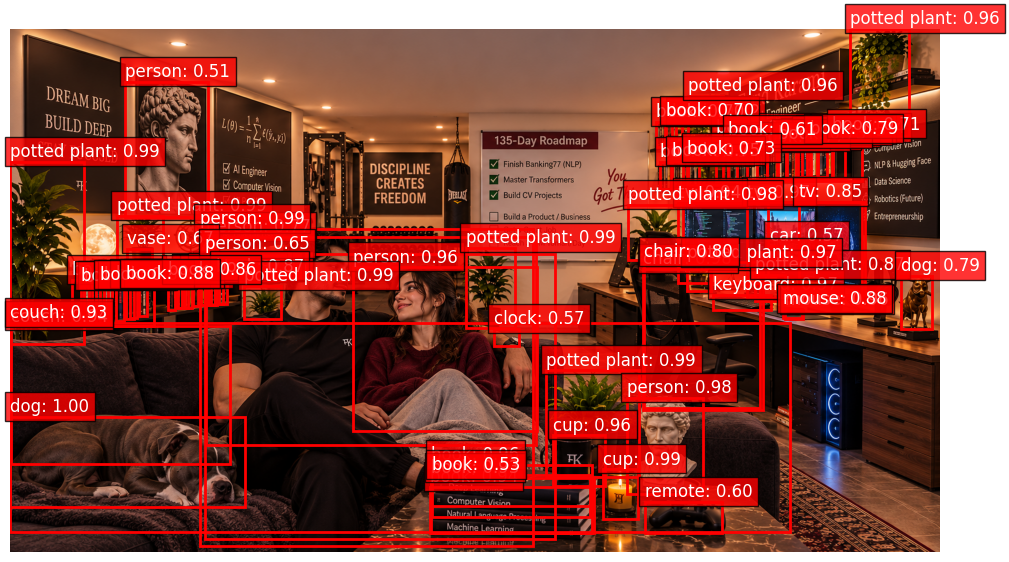

In [28]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

image = Image.open(picture).convert("RGB")

fig, ax = plt.subplots(1, figsize=(12, 8))
ax.imshow(image)

for detected in result:
    box = detected["box"]

    x1 = box["xmin"]
    y1 = box["ymin"]
    x2 = box["xmax"]
    y2 = box["ymax"]

    rectangle = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rectangle)

    ax.text(
        x1,
        y1 - 10,
        f'{detected["label"]}: {detected["score"]:.2f}',
        color="white",
        fontsize=12,
        bbox=dict(facecolor="red", alpha=0.8)
    )

plt.axis("off")
plt.show()

In [29]:
import torch
from transformers import pipeline

fill_mask = pipeline(
    task = "fill-mask",
    model = "bert-base-uncased",
    device = 0 if torch.cuda.is_available() else -1
)

mask = fill_mask.tokenizer.mask_token

texts = [
    f"The capital of France is {mask}.",
    f"She drank {mask} in the morning."
]

results = fill_mask(texts, top_k = 1)


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [30]:
print(len(results))

2


In [31]:
for i in range(len(results)):
  for result in results[i]:
    print("Sentence -> ",result["sequence"],",",result["token_str"], ": ", result["score"])


Sentence ->  the capital of france is paris. , paris :  0.4167884886264801
Sentence ->  she drank it in the morning. , it :  0.2010129690170288


In [32]:
text = "He was licking his wife's wet [MASK], while she was saying enough please fuck me."

results = fill_mask(
    text,
    targets = ["dick", "sperm", "pussy", "finger", "balls", "lips"],
    top_k = 1
)


print(results)


[{'score': 0.32203492522239685, 'token': 22418, 'token_str': 'pussy', 'sequence': "he was licking his wife ' s wet pussy, while she was saying enough please fuck me."}]


In [33]:
texts = [
    f"She ate her husband's big black {mask} while he fucked her face, he was naked and she was in 69 position, her husband was licking her pussy", # Correct answer Dick
    f"She ate her husband's  {mask} when he came home" # Correct answer Food
]

results = fill_mask(
    texts,
    top_k = 1
)
for i in range(len(results)):
  for result in results[i]:
    print(result["token_str"], result["score"], "Done\n")

cock 0.1688748449087143 Done

food 0.09614254534244537 Done



In [34]:
generator = pipeline(
    task = "text-generation",
    model = "gpt2",
    device = 0 if torch.cuda.is_available() else -1
)

text = "She was in love with her husband's big black"

result = generator(text, max_new_tokens = 50)
print(result)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'generated_text': "She was in love with her husband's big black girlfriend, a guy named Chris, and was at a party with him when he was raped. He and his friends had a party at the same party, and when Chris was assaulted and knocked unconscious, he managed to escape.\n\nShe spent the"}]


In [35]:
from transformers import pipeline

generator = pipeline(
    task = "text-generation",
    model = "gpt2",
    device = 0 if torch.cuda.is_available() else -1
)

text = "I need to live in peace once again but"


result = generator(text, max_new_tokens = 50)
print(result)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[{'generated_text': 'I need to live in peace once again but the world is not ready to accept that.\n\nJOHANNESBURG, Germany (AP) — Two German soldiers who went on hunger strike in Germany this week said they have no hope of being released after being held without charges for six'}]


In [36]:
from transformers import pipeline
import torch

generator = pipeline(task = "text-generation", model="openai-community/gpt2", device = (0 if torch.cuda.is_available() else -1))
prompt = "Tehran is capital of "
result = generator(prompt, max_new_tokens= 5 , num_return_sequences= 3, do_sample=True)
print(result)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'generated_text': 'Tehran is capital of ichun, a large'}, {'generated_text': 'Tehran is capital of ich-Germans'}, {'generated_text': 'Tehran is capital of vernacular Persian-language'}]


In [37]:
generator = pipeline(
    task = "text-generation",
    model = "openai-community/gpt2",
    device= 0 if torch.cuda.is_available() else -1)

few_prompt = "Country: Iran, Capital: Tehran, Country: Japan, Capital: Tokyo, Country: Italy, capital:"

result = generator(few_prompt, max_new_tokens=1, num_return_sequences =1)
print(result[0]["generated_text"])

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Country: Iran, Capital: Tehran, Country: Japan, Capital: Tokyo, Country: Italy, capital: Rome


In [38]:
prompt_role = "system: you are an agressive commander. \nUser:Hello I am tired, \nAssitant:"
output= generator(prompt_role, max_new_tokens = 50, num_return_sequences=1)
print(output[0]["generated_text"])

system: you are an agressive commander. 
User:Hello I am tired, 
Assitant: You are an agressive commander?
User:Is there anyone here who believes in 
Assitant:  that the 
Assitant:  is  my 
Assitant:  that 
Assitant:


In [39]:
import torch
from transformers import pipeline

generator = pipeline(
    task = "text-generation",
    model = "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    device = 0 if torch.cuda.is_available() else -1
)

MESSAGES = [
    {"role": "system", "content": "Calculate the sum of the numbers in the list. Reply with only the number."},
    {"role": "user", "content": "[1, 2, 3]"},
    {"role": "assistant", "content": "6"},
    {"role": "user", "content": "[2, 4, 6, 10]"},
    {"role": "assistant", "content": "22"},
    {"role": "user", "content": "[5, 5, 5]"},
    {"role": "assistant", "content": "15"},
    {"role": "user", "content": "[10, 12, 14]"},
]

result = generator(MESSAGES, max_new_tokens=10, do_sample=False)
print(result[0]["generated_text"][-1]["content"])


print("----------------------------------------")


prompt = generator.tokenizer.apply_chat_template(MESSAGES, tokenize=False, add_generation_prompt=True)
result = generator(MESSAGES, max_new_tokens=30, do_sample=False)

print(result[0]["generated_text"][-1]["content"])

print("----------------------------------------")

print(prompt)

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.20GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=10) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=30) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


20
----------------------------------------
20
----------------------------------------
<|system|>
Calculate the sum of the numbers in the list. Reply with only the number.</s>
<|user|>
[1, 2, 3]</s>
<|assistant|>
6</s>
<|user|>
[2, 4, 6, 10]</s>
<|assistant|>
22</s>
<|user|>
[5, 5, 5]</s>
<|assistant|>
15</s>
<|user|>
[10, 12, 14]</s>
<|assistant|>



In [40]:
text = generator.tokenizer.apply_chat_template(MESSAGES, tokenize=False, add_generation_prompt=True)
print(text)

<|system|>
Calculate the sum of the numbers in the list. Reply with only the number.</s>
<|user|>
[1, 2, 3]</s>
<|assistant|>
6</s>
<|user|>
[2, 4, 6, 10]</s>
<|assistant|>
22</s>
<|user|>
[5, 5, 5]</s>
<|assistant|>
15</s>
<|user|>
[10, 12, 14]</s>
<|assistant|>



In [41]:
ids = generator.tokenizer.apply_chat_template(MESSAGES, tokenize=True, add_generation_prompt=True)
print(ids)

{'input_ids': [529, 29989, 5205, 29989, 29958, 13, 27065, 403, 278, 2533, 310, 278, 3694, 297, 278, 1051, 29889, 10088, 368, 411, 871, 278, 1353, 29889, 2, 13, 29966, 29989, 1792, 29989, 29958, 13, 29961, 29896, 29892, 29871, 29906, 29892, 29871, 29941, 29962, 2, 13, 29966, 29989, 465, 22137, 29989, 29958, 13, 29953, 2, 13, 29966, 29989, 1792, 29989, 29958, 13, 29961, 29906, 29892, 29871, 29946, 29892, 29871, 29953, 29892, 29871, 29896, 29900, 29962, 2, 13, 29966, 29989, 465, 22137, 29989, 29958, 13, 29906, 29906, 2, 13, 29966, 29989, 1792, 29989, 29958, 13, 29961, 29945, 29892, 29871, 29945, 29892, 29871, 29945, 29962, 2, 13, 29966, 29989, 465, 22137, 29989, 29958, 13, 29896, 29945, 2, 13, 29966, 29989, 1792, 29989, 29958, 13, 29961, 29896, 29900, 29892, 29871, 29896, 29906, 29892, 29871, 29896, 29946, 29962, 2, 13, 29966, 29989, 465, 22137, 29989, 29958, 13], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [42]:
from transformers import pipeline

corpus = [
    "how can you find a car for youself, Finding a car is an exhustive action it takes ours spending on social media and different webiste until you can find your favorite car",
    "AI is changing world too fast, but people are not ready for, As far as we know normal people use AI to generate pictures or decide instead of them",
    "Iran, is the only contry in the world that decides to sacrifice its people needs to save other people in on the other side of the world",
    "Farid is an AI engineer and an English teacher, he has spent his life teaching people and models",
]



def retrive_document(query: str, document: ["str"]) -> str:
  best_match = ""
  highest_overlap = 0
  query_set = set(query.lower().split())

  for doc in document:

    doc_set = set(doc.lower().split())
    overlap = len(query_set.intersection(doc_set))

    if overlap > highest_overlap:
      highest_overlap = overlap
      best_match = doc

  return best_match


user_question = "What is AI doing right now?"
relevent_text = retrive_document(user_question, corpus)

def create_rag_prompt(context, query):
  return "Context: "+ context + "\nQuestion: " + query + "\nAnswer: "

rag_prompt = create_rag_prompt(relevent_text, user_question)



llm = pipeline(task = "text-generation", model = "TinyLlama/TinyLlama-1.1B-Chat-v1.0")

generation = llm(rag_prompt, max_new_tokens= 50, do_sample = False)

print(generation[0]["generated_text"])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Context: AI is changing world too fast, but people are not ready for, As far as we know normal people use AI to generate pictures or decide instead of them
Question: What is AI doing right now?
Answer: 1. Chatbots: AI is already doing a lot of work in chatbots. It is helping businesses to provide better customer service, and it is also helping to improve the accuracy of customer feedback.
2. Voice


In [53]:
message = [
    {"role": "system", "content": "answer the question only with the content provided, if the content does not have the reliable answer you can just politley say I don't know"},
    {"role": "user", "content": f"content:{relevent_text}\nQuestion: {user_question}"},
    {"role": "user", "content": "Using only the text below, answer is one sentence"}
]

call_llm = pipeline(
    task = "text-generation",
    model = "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    device = 0 if torch.cuda.is_available() else -1
)

result = call_llm(message, max_new_tokens = 50, do_sample =False)
print(result[0]["generated_text"][-1]["content"])

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


AI is doing a lot of things right now, but people are not ready for it.
